# Copy-number variation from scATAC-seq (epiAneufinder)

Tumour cells gain and lose whole chromosomes and chromosome arms. In scATAC-seq data a gained
region gives proportionally more fragments and a lost region fewer, so the read depth along the
genome carries a copy-number profile for every cell. [epiAneufinder](https://github.com/colomemaria/epiAneufinder)
(Ramakrishnan, Symeonidi, Hanel *et al.*, *Nat. Commun.* 14, 5846, 2023) turns this into per-cell
gain / normal / loss calls:

1. tile the genome into 100 kb windows, drop blacklisted windows and windows with N bases, count
   fragments per window and cell;
2. drop cells with too few covered windows and windows that are empty in most cells;
3. remove the GC bias of each cell with a LOESS fit of counts on window GC content;
4. segment each chromosome of each cell by recursive binary splitting: the split point is the
   position with the largest Anderson–Darling distance between the count distributions left and
   right of it, repeated `k = 4` times (up to 16 segments per chromosome);
5. keep the breakpoints whose distance is above the cell's mean (positive z-score);
6. call each segment loss (0), normal (1) or gain (2) from its trimmed mean relative to the
   genome-wide mean.

`epi.tl.cnv` is a port of the R package (version 1.1.5, GPL-3). Against R on the data of this
tutorial it reproduces the windows, counts, GC-corrected counts, breakpoints and CNV states
exactly; the gate table is at the end and in `tests/parity/epianeufinder/MANIFEST.md`.

The data are the SNU601 gastric cancer cell line profiled with 10x scATAC-seq
(SRA [PRJNA674903](https://www.ncbi.nlm.nih.gov/bioproject/PRJNA674903)), the main dataset of the
epiAneufinder paper.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pooch

import epione as epi

pooch.get_logger().setLevel("WARNING")
DATA = Path(os.environ.get("EPIONE_DATA_DIR", pooch.os_cache("epione"))) / "cnv_snu601"
DATA.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get("EPIONE_N_JOBS", "8"))

# epiAneufinder's sample data (16 SNU601 cells) and the ENCODE hg38 blacklist it ships with
EAF = "https://raw.githubusercontent.com/colomemaria/epiAneufinder/47293f7/sample_data/"
blacklist = pooch.retrieve(EAF + "hg38-blacklist.v2.bed", path=DATA, progressbar=False,
    known_hash="sha256:31c69342df43bbc19dd8ef2886611a8150cb53e90f341de14d30e742c9251737")
sample_tsv = pooch.retrieve(EAF + "sample.tsv", path=DATA, progressbar=False,
    known_hash="sha256:3f45526c87d2743ad2ff2951f44e176e7fa1aaacb207bb36b3a75b7522f2afc2")

# UCSC hg38 (the sequence of BSgenome.Hsapiens.UCSC.hg38, which R epiAneufinder uses)
hg38 = os.environ.get("EPIONE_HG38_FASTA")
if hg38 is None:
    hg38 = pooch.retrieve(
        "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.fa.gz", known_hash=None,
        path=DATA, processor=pooch.Decompress(name="hg38.fa"), progressbar=False)

## Genome windows

`epi.tl.cnv_make_windows` tiles chr1–chr22 into 100 kb windows (chrX, chrY and chrM are excluded
as in epiAneufinder's example script), removes the windows that overlap the blacklist and records
the GC, AT and N fraction of each window. The table can be reused for every sample on the same
genome.

In [2]:
t = time.perf_counter()
windows = epi.tl.cnv_make_windows(hg38, blacklist, window_size=100_000,
                                  exclude=["chrX", "chrY", "chrM"])
print(f"{len(windows)} windows in {time.perf_counter() - t:.0f} s")
windows.head()

26445 windows in 32 s


,chrom,start,end,tile,GC,AT,N
0,chr1,800000,900000,8,0.44823,0.55177,0.0
1,chr1,900000,1000000,9,0.62123,0.37877,0.0
2,chr1,1000000,1100000,10,0.62746,0.37254,0.0
3,chr1,1100000,1200000,11,0.58992,0.41008,0.0
4,chr1,1200000,1300000,12,0.62685,0.37315,0.0


## A first run on the epiAneufinder sample data

The package ships a fragments file with 16 SNU601 cells. `epi.tl.cnv` returns an AnnData of
cells x windows: `X` holds the state per window (0 loss, 1 normal, 2 gain), `layers` the raw and
GC-corrected counts, `var` the windows with their GC content and `uns['cnv']` the breakpoints and
parameters. The defaults are those of the R function (`test="AD"`, `k=4`, `minFrags=20000`, ...).

In [3]:
small = epi.tl.cnv(sample_tsv, windows=windows, window_size=100_000, n_jobs=4)
small

[cnv] counting into 26445 windows ...


[cnv] 16 cells x 24558 windows after filtering
[cnv] GC correction + segmentation (AD) on 4 worker(s) ...


[cnv] done in 1.2s


AnnData object with n_obs × n_vars = 16 × 24558
    obs: 'n_fragments', 'cnv_burden'
    var: 'chrom', 'start', 'end', 'GC', 'AT', 'N'
    uns: 'cnv'
    layers: 'counts', 'gc_corrected'

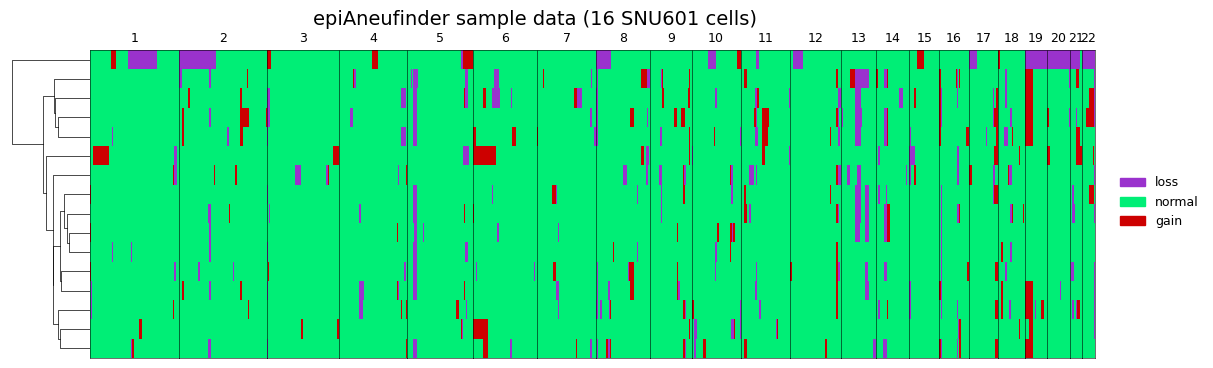

In [4]:
fig = epi.pl.karyogram(small, title="epiAneufinder sample data (16 SNU601 cells)", figsize=(14, 4))

## The full SNU601 dataset

SRA hosts the Cell Ranger ATAC `possorted_bam.bam` of the sample (59 GB). The cell below turns
it into a 10x-style fragments file: properly paired reads with MAPQ ≥ 30 and a `CB` tag, Tn5 shift
of +4/−5, fragment length 10–5000 bp, duplicates collapsed. Set `EPIONE_SNU601_FRAGMENTS` to an
existing fragments file to skip it, or `EPIONE_SNU601_BAM` to a downloaded BAM
(`https://sra-pub-src-2.s3.amazonaws.com/SRR12995620/SNU601_scATAC.possorted_bam.bam.1`).

In [5]:
import collections
from multiprocessing import Pool

import pysam


def _fragments_one_chrom(args):
    bam, chrom, out = args
    counts = collections.Counter()
    for r in pysam.AlignmentFile(bam).fetch(chrom):
        if (not r.is_proper_pair or r.is_secondary or r.is_supplementary or r.is_unmapped
                or r.mapping_quality < 30 or r.template_length <= 0 or not r.has_tag("CB")):
            continue
        s, e = r.reference_start + 4, r.reference_start + r.template_length - 5
        if 10 <= e - s <= 5000:
            counts[(s, e, r.get_tag("CB"))] += 1
    with open(out, "w") as fh:
        for (s, e, cb), n in sorted(counts.items()):
            fh.write(f"{chrom}\t{s}\t{e}\t{cb}\t{n}\n")
    return out


def bam_to_fragments(bam, out, n_jobs=8):
    chroms = [c for c in pysam.AlignmentFile(bam).references
              if c.removeprefix("chr").isdigit() or c in ("chrX", "chrY")]
    with Pool(n_jobs) as pool:
        parts = pool.map(_fragments_one_chrom, [(bam, c, f"{out}.{c}.tmp") for c in chroms])
    with open(out, "w") as fo:
        for p in parts:
            with open(p) as fi:
                fo.write(fi.read())
            os.remove(p)
    return out


fragments = Path(os.environ.get("EPIONE_SNU601_FRAGMENTS", DATA / "SNU601_fragments.tsv"))
if not fragments.exists():
    bam_to_fragments(os.environ["EPIONE_SNU601_BAM"], fragments, n_jobs=N_JOBS)
print(fragments.name, f"{fragments.stat().st_size / 1e9:.1f} GB")

fragments.tsv 13.9 GB


In [6]:
t = time.perf_counter()
cnv = epi.tl.cnv(fragments, windows=windows, window_size=100_000, n_jobs=N_JOBS)
print(f"{time.perf_counter() - t:.0f} s with {N_JOBS} workers")
pd.Series(cnv.uns["cnv"]["timings"]).round(1)

[cnv] counting into 26445 windows ...


[cnv] 3160 cells x 26003 windows after filtering
[cnv] GC correction + segmentation (AD) on 8 worker(s) ...


[cnv] done in 235.5s
240 s with 8 workers


windows           0.0
counts          218.9
segmentation     16.6
total           235.5
dtype: float64

In [7]:
print(cnv)
states = np.asarray(cnv.X)
vals, cnts = np.unique(states, return_counts=True)
print("calls per state:", {["loss", "normal", "gain"][int(v)]: int(c) for v, c in zip(vals, cnts)})
cnv.obs.describe().round(3)

AnnData object with n_obs × n_vars = 3160 × 26003
    obs: 'n_fragments', 'cnv_burden'
    var: 'chrom', 'start', 'end', 'GC', 'AT', 'N'
    uns: 'cnv'
    layers: 'counts', 'gc_corrected'


calls per state: {'loss': 4092435, 'normal': 71271973, 'gain': 6805072}


,n_fragments,cnv_burden
count,3160.000,3160.000
mean,91584.634,0.133
std,54077.673,0.057
min,20070.000,0.000
25%,56656.750,0.097
50%,82844.000,0.136
75%,110923.000,0.170
max,561581.000,0.510


## Subclones and the karyogram

`epi.tl.cnv_subclones` is epiAneufinder's `split_subclones`: Ward clustering (`ward.D`) of the
Euclidean distances between the CNV profiles, cut into `n_clones` groups. R's `hclust` and
`cutree` are ported, so the groups and the dendrogram order are those of R. The karyogram orders the
cells by that dendrogram, as epiAneufinder's `Karyogram.png` does, with the subclones as an
annotation bar.

In [8]:
for k in (2, 3, 4):
    epi.tl.cnv_subclones(cnv, n_clones=k, key_added=f"subclone_k{k}")
cnv.obs["subclone"] = cnv.obs["subclone_k3"]
cnv.obs["subclone"].value_counts().sort_index()

subclone
1     470
2    2405
3     285
Name: count, dtype: int64

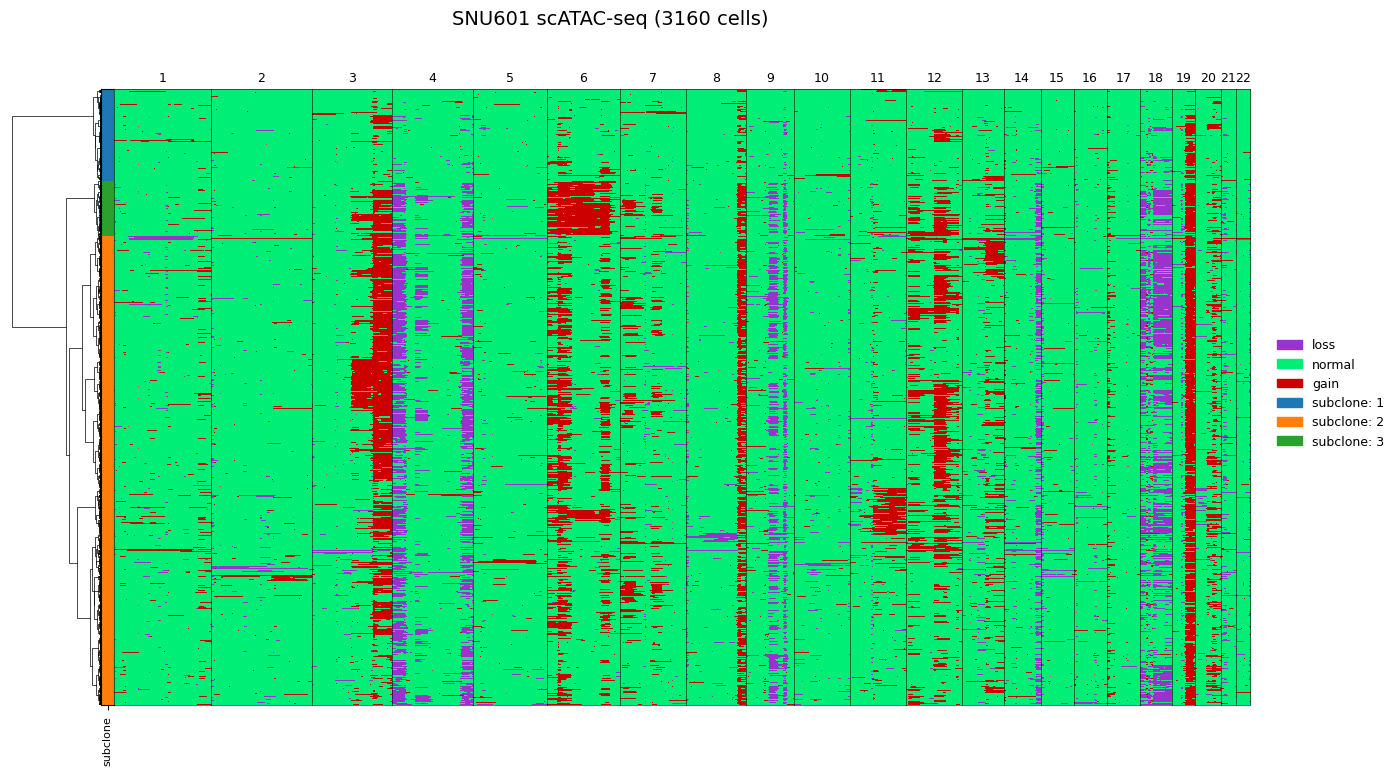

In [9]:
fig = epi.pl.karyogram(cnv, groupby="subclone", title=f"SNU601 scATAC-seq ({cnv.n_obs} cells)",
                       figsize=(16, 8))

The consensus profile of each subclone shows which events separate them: the fraction of cells
with a gain minus the fraction with a loss, per window.

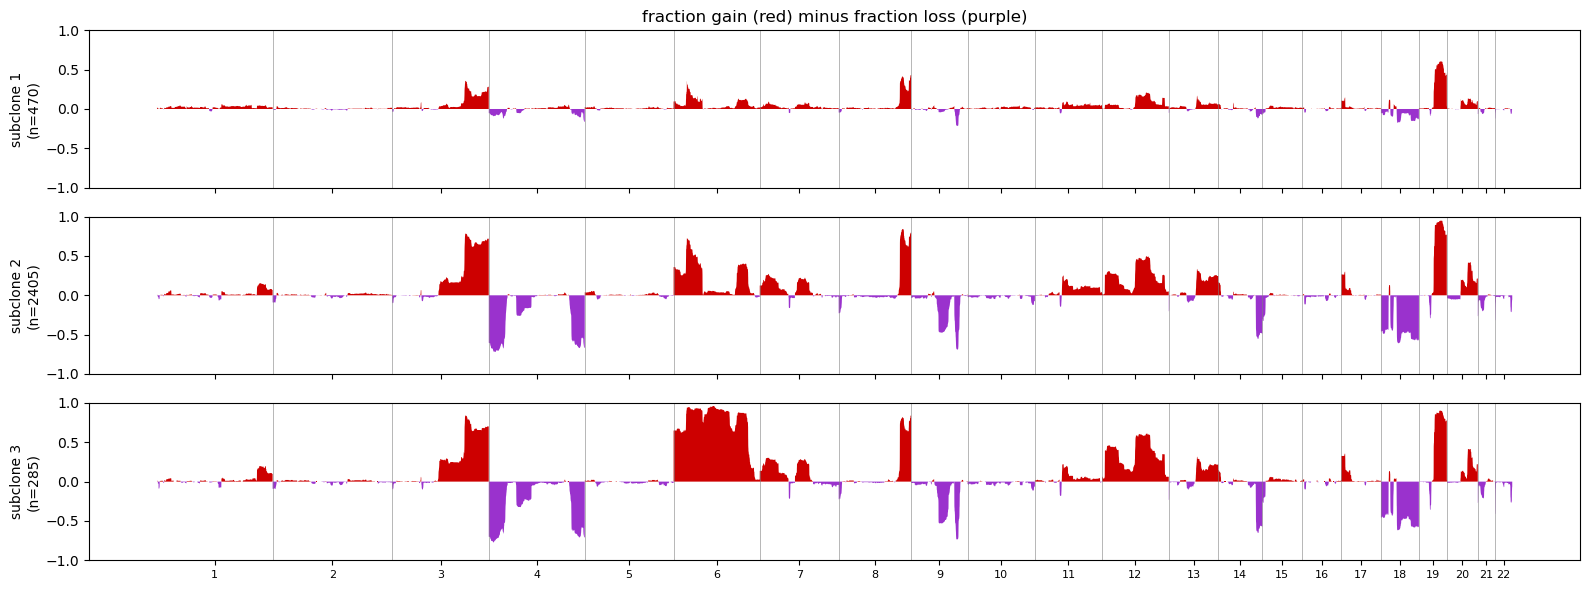

In [10]:
chrom = cnv.var["chrom"].astype(str).to_numpy()
edges = np.flatnonzero(np.r_[True, chrom[1:] != chrom[:-1], True])
fig, axes = plt.subplots(3, 1, figsize=(16, 6), sharex=True, sharey=True)
for ax, (g, idx) in zip(axes, cnv.obs.groupby("subclone", observed=True).indices.items()):
    S = states[idx]
    prof = (S == 2).mean(0) - (S == 0).mean(0)
    ax.fill_between(np.arange(prof.size), prof, where=prof > 0, color="#CD0000", lw=0)
    ax.fill_between(np.arange(prof.size), prof, where=prof < 0, color="#9A32CD", lw=0)
    for e in edges[1:-1]:
        ax.axvline(e, color="grey", lw=0.4)
    ax.set_ylabel(f"subclone {g}\n(n={idx.size})")
    ax.set_ylim(-1, 1)
axes[-1].set_xticks((edges[:-1] + edges[1:]) / 2)
axes[-1].set_xticklabels([c.removeprefix("chr") for c in chrom[edges[:-1]]], fontsize=8)
axes[0].set_title("fraction gain (red) minus fraction loss (purple)")
plt.tight_layout()

## Aneuploidy and heterogeneity

`epi.tl.cnv_karyotype_measures` gives epiAneufinder's karyotype measures: aneuploidy is the
fraction of calls that are not normal, and heterogeneity per window is the AneuFinder score
(Bakker *et al.* 2016), which is 0 when all cells share the state and grows with the number of
cells outside the most frequent state. Chromosomes with a clonal event have high aneuploidy and
low heterogeneity; subclonal events raise both.

,Aneuploidy,Heterogeneity
0,0.133,0.123


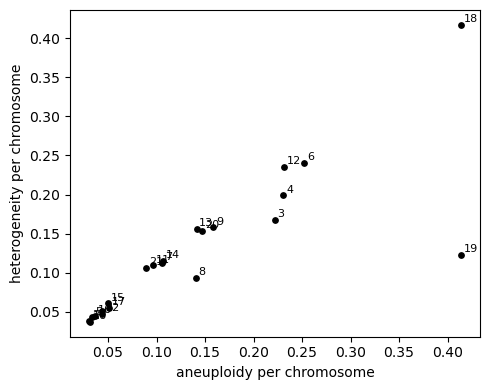

In [11]:
km = epi.tl.cnv_karyotype_measures(cnv)
display(km["genomewide"].round(3))
per = km["per_chromosome"]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(per["Aneuploidy"], per["Heterogeneity"], s=15, color="black")
for c, r in per.iterrows():
    ax.annotate(c.removeprefix("chr"), (r["Aneuploidy"], r["Heterogeneity"]), fontsize=8,
                xytext=(2, 2), textcoords="offset points")
ax.set_xlabel("aneuploidy per chromosome")
ax.set_ylabel("heterogeneity per chromosome")
plt.tight_layout()

## A single cell

`epi.pl.cnv_profile` plots the GC-corrected counts of one cell, coloured by the called state
(the lower panel of epiAneufinder's `plot_single_cell_profile`).

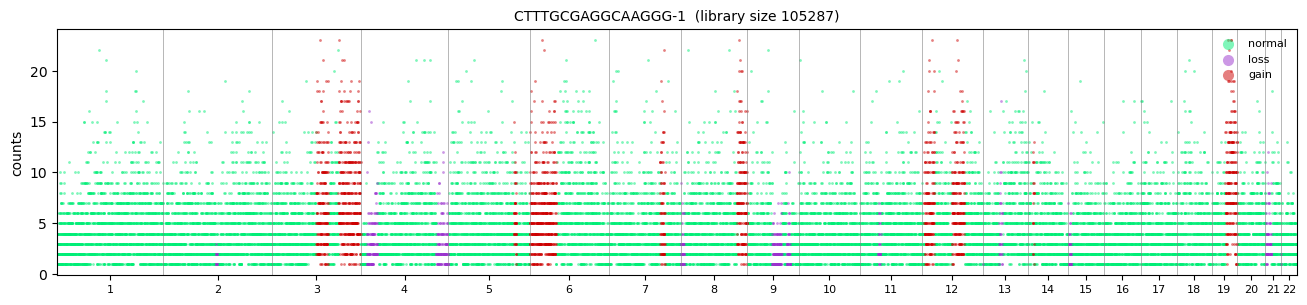

In [12]:
cell = cnv.obs["cnv_burden"].sort_values().index[len(cnv.obs) // 2]
ax = epi.pl.cnv_profile(cnv, cell)

## Using the calls with other analyses

`epi.tl.cnv(..., adata=atac)` also writes the states into an existing AnnData of the same cells:
`atac.obsm["X_cnv"]` (NaN for cells removed by the CNV filters), `atac.obs["cnv_burden"]` and the
window table in `atac.uns["cnv"]`. The subclone labels can then be used like any other cell
annotation, for example to compare accessibility between subclones.

## Agreement with R epiAneufinder

The R package (1.1.5, R 4.4.3, `BSgenome.Hsapiens.UCSC.hg38`) and `epi.tl.cnv` were run on the same
fragments with the same parameters. The gates were fixed before the comparison
(`tests/parity/epianeufinder/MANIFEST.md`).

| Gate | Output | Threshold | D1 sample (AD) | D2 SNU601 (AD) | D3 sample (KS) | Pass |
|---|---|---|---|---|---|---|
| G0a | windows, cells after filters | identical | identical (16 cells × 24558 windows) | identical (3160 cells × 26003 windows) | identical (16 cells × 24558 windows) | yes |
| G0b | GC / AT / N per window | max abs ≤ 1e-12 | 1.11e-16 | 1.11e-16 | 1.11e-16 | yes |
| G0c | raw counts | identical | identical | identical | identical | yes |
| G0d | GC-corrected counts | equal ≥ 0.9999, max diff ≤ 1 | 1.0 equal, max diff 0 | 1.0 equal, max diff 0 | 1.0 equal, max diff 0 | yes |
| G1a | `getbp` breakpoints per cell × chromosome (R input) | identical in ≥ 99.9 % | 1.0 of 352 | 1.0 of 69520 | 1.0 of 352 | yes |
| G1b | breakpoint distances | max rel ≤ 1e-10 | 5.00e-16 | 1.19e-15 | 2.46e-16 | yes |
| G1c | pruned breakpoints, end-to-end | Jaccard (±1 bin) ≥ 0.99 | 1.0 (exact positions 1.0) | 1.0 (exact positions 1.0) | 1.0 (exact positions 1.0) | yes |
| G2a | CNV state per cell × window, end-to-end | agreement ≥ 0.99 | 1.0 | 1.0 | 1.0 | yes |
| G2b | CNV state given R's GC-corrected counts | agreement ≥ 0.999 | 1.0 | 1.0 | 1.0 | yes |
| G3a | subclones (`split_subclones`) | ARI ≥ 0.95 | 1.0 (k = 2–6) | 1.0 (k = 2–6) | 1.0 (k = 2–6) | yes |
| G3b | karyotype measures | max abs ≤ 1e-6 | 5.00e-16 | 5.00e-16 | 9.75e-17 | yes |

D1 is epiAneufinder's sample data, D2 the full SNU601 dataset of this tutorial and D3 the sample
data with the Kolmogorov–Smirnov test (`test="KS"`). On D2, R took about 4 hours to the CNV table
(38.9 s of segmentation per cell and core) and `epi.tl.cnv` 264 s with 24 workers (381 s with one);
the subclone split for k = 2..6 took 5,307 s in R and 12 s here.